# Segmenting busy Karachi roads with Cityscapes‑trained models

**Goal.** Take real photographs of Karachi traffic, segment every object in them with two state‑of‑the‑art
Cityscapes‑trained networks, and analyse (a) *what* the models see — vehicles, people, road, buildings — and
(b) *how well* a dataset built from **50 European cities** transfers to a South‑Asian megacity.

| | |
|---|---|
| **Semantic model** | `nvidia/segformer-b2-finetuned-cityscapes-1024-1024` — SegFormer (Xie et al., NeurIPS 2021), hierarchical Transformer encoder + all‑MLP decoder, 19 Cityscapes classes |
| **Panoptic model** | `facebook/mask2former-swin-tiny-cityscapes-panoptic` — Mask2Former (Cheng et al., CVPR 2022), masked‑attention Transformer decoder; gives *stuff* + *thing instances* = **panoptic segmentation** (Kirillov et al., CVPR 2019) |
| **Images** | 22 Creative‑Commons / Free‑Art‑licensed photographs of Karachi roads from Wikimedia Commons (see `data/karachi_raw/MANIFEST.csv` for author + licence of every file) |
| **Hardware** | runs on a 6 GB laptop GPU; CPU fallback works but is slow |

## 1. How Cityscapes represents 50 cities

Cityscapes (Cordts et al., CVPR 2016) is the reference benchmark for urban‑scene understanding:

* **50 cities**, almost all in **Germany** plus **Zürich (CH)** and **Strasbourg (FR)**. The *fine* split uses 27 cities — train: Aachen, Bochum, Bremen, Cologne, Darmstadt, Düsseldorf, Erfurt, Hamburg, Hanover, Jena, Krefeld, Mönchengladbach, Strasbourg, Stuttgart, Tübingen, Ulm, Weimar, Zürich; val: Frankfurt, Lindau, Münster; test: Berlin, Bielefeld, Bonn, Leverkusen, Mainz, Munich. The remaining 23 cities (e.g. Saarbrücken, Nuremberg, Erlangen, Bamberg, Dortmund on the examples page) appear only in the *coarse* split.
* **5,000 finely annotated** frames (pixel‑accurate polygons, ≈1.5 h of labelling each) + **20,000 coarsely annotated** frames; 2048×1024 px stereo video, the annotated frame is the 20th of a 30‑frame snippet, with GPS, odometry and temperature metadata.
* Captured from a car, **daytime, spring–autumn, good/medium weather** — no night, rain or snow.
* **30 classes in 8 groups**; 19 are used for evaluation (the `+` classes are mapped to *void*), 8 of them with instance labels (`*`):

| group | classes |
|---|---|
| flat | road, sidewalk, parking⁺, rail track⁺ |
| human | person\*, rider\* |
| vehicle | car\*, truck\*, bus\*, on rails\*, motorcycle\*, bicycle\*, caravan\*⁺, trailer\*⁺ |
| construction | building, wall, fence, guard rail⁺, bridge⁺, tunnel⁺ |
| object | pole, pole group⁺, traffic sign, traffic light |
| nature | vegetation, terrain |
| sky | sky |
| void | ground⁺, dynamic⁺, static⁺ |

The result is a *consistent* but *geographically narrow* representation of “a city street”: right‑hand traffic, lane
markings, sedans and hatchbacks, cyclists on cycle lanes, few pedestrians on the carriageway. Karachi differs on
almost every one of those axes (left‑hand traffic, auto‑rickshaws/qingqis, motorbikes carrying families, decorated
buses with roof passengers, hawkers and pedestrians sharing the road, dust/haze) — which is exactly what makes it a
good stress test.

## 2. Privacy & ethics
* The photos are **public, openly licensed** images of public roads; none were taken for this project and no person is identified. Each file's author and licence are recorded in `MANIFEST.csv` and shown in the figures.
* Before any analysis the notebook **pixelates faces and number plates** (OpenCV Zoo's YuNet face detector and LPD‑YuNet plate detector, run through `cv2.dnn`), and after panoptic segmentation it additionally **pixelates the head region of every detected person and the plate zone of every detected vehicle** — the same “blur for privacy” practice Cityscapes applies to its released videos.
* Outputs are *aggregate* statistics (pixel shares, object counts); no tracking, re‑identification or attribute inference is attempted.
* If you add your own photos: shoot from a public place, avoid framing individuals, do not photograph children deliberately, keep plates unreadable, and delete originals once the anonymised copies exist.

## 3. Setup

In [1]:
import os, sys, time, json, math, csv, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn.functional as F
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| opencv", cv2.__version__, "| device", DEVICE)

RAW_DIR   = Path("../data/karachi_raw")          # downloaded photos + MANIFEST.csv
ANON_DIR  = Path("../data/karachi_anon")         # face/plate-blurred copies (what the models see)
ANON_MODELS = Path("../data/anonymizer")         # OpenCV Zoo YuNet face + licence-plate detectors (ONNX)
OUT_DIR   = Path("../outputs/karachi"); OUT_DIR.mkdir(parents=True, exist_ok=True)
SEGFORMER_ID = "nvidia/segformer-b2-finetuned-cityscapes-1024-1024"
M2F_ID       = "facebook/mask2former-swin-tiny-cityscapes-panoptic"

manifest = pd.read_csv(RAW_DIR / "MANIFEST.csv")
manifest = manifest[manifest.file.apply(lambda f: (RAW_DIR / f).exists() and (RAW_DIR / f).stat().st_size > 0)].reset_index(drop=True)
print(len(manifest), "images available")
manifest[["file", "commons_title", "author", "license", "date"]]

torch 2.14.1+cu126 | opencv 5.0.0 | device cuda
22 images available


,file,commons_title,author,license,date
0,karachi_01.jpg,File:Karachi street scene.jpg,Jan Kranendonk (https://www.jankranendonk.nl),CC BY-SA 4.0,1987
1,karachi_02.jpg,File:Busy day in Sadar 2017.jpg,Insia.rakla,CC BY-SA 4.0,2017-03-15
2,karachi_03.jpg,File:Busy road of saddar.jpg,Insia.rakla,CC BY-SA 4.0,2017-03-15
3,karachi_04.jpg,File:Federal B Area Karachi.jpg,King Eliot,CC BY-SA 4.0,2018-07-29
4,karachi_05.jpg,"File:M. A. Jinnah Road, Karachi.jpg",Siddiqi,CC BY-SA 4.0,2016-01-18
5,karachi_06.jpg,File:Traffic under the Nagan Flyover - panoram...,Anwar Ahmed,CC BY-SA 3.0,Taken on 3
6,karachi_07.jpg,File:More Karachi Main.jpg,"V Malik from New Delhi & Pune, India",CC BY-SA 2.0,2009-11-02
7,karachi_08.jpg,File:Rickshaw Pakistan Karachi.jpg,"V Malik from New Delhi & Pune, India",CC BY-SA 2.0,2009-11-02
8,karachi_09.jpg,File:Bus Karachi drive-through.jpg,"V Malik from New Delhi & Pune, India",CC BY-SA 2.0,2009-11-02
9,karachi_10.jpg,File:Karachi street photos.jpg,"V Malik from New Delhi & Pune, India",CC BY-SA 2.0,2009-10-29


### 3.1 Cityscapes label set (19 evaluation classes) and official colour palette

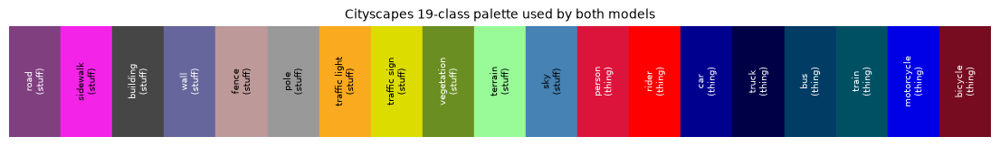

In [2]:
CITYSCAPES = [  # (train id, name, colour, group, is_thing)
    (0, "road", (128, 64, 128), "flat", False),        (1, "sidewalk", (244, 35, 232), "flat", False),
    (2, "building", (70, 70, 70), "construction", False), (3, "wall", (102, 102, 156), "construction", False),
    (4, "fence", (190, 153, 153), "construction", False), (5, "pole", (153, 153, 153), "object", False),
    (6, "traffic light", (250, 170, 30), "object", False), (7, "traffic sign", (220, 220, 0), "object", False),
    (8, "vegetation", (107, 142, 35), "nature", False), (9, "terrain", (152, 251, 152), "nature", False),
    (10, "sky", (70, 130, 180), "sky", False),         (11, "person", (220, 20, 60), "human", True),
    (12, "rider", (255, 0, 0), "human", True),         (13, "car", (0, 0, 142), "vehicle", True),
    (14, "truck", (0, 0, 70), "vehicle", True),        (15, "bus", (0, 60, 100), "vehicle", True),
    (16, "train", (0, 80, 100), "vehicle", True),      (17, "motorcycle", (0, 0, 230), "vehicle", True),
    (18, "bicycle", (119, 11, 32), "vehicle", True)]
NAMES   = [c[1] for c in CITYSCAPES]
PALETTE = np.array([c[2] for c in CITYSCAPES], dtype=np.uint8)
GROUP   = {c[1]: c[3] for c in CITYSCAPES}
THINGS  = [c[1] for c in CITYSCAPES if c[4]]

fig, ax = plt.subplots(figsize=(14, 1.6))
for i, (tid, name, col, grp, thing) in enumerate(CITYSCAPES):
    ax.add_patch(mpatches.Rectangle((i, 0), 1, 1, color=np.array(col) / 255))
    ax.text(i + .5, .5, f"{name}\n{'(thing)' if thing else '(stuff)'}", ha="center", va="center", fontsize=7, color="white" if sum(col) < 380 else "black", rotation=90)
ax.set_xlim(0, 19); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title("Cityscapes 19-class palette used by both models", fontsize=10)
plt.show()

## 4. Image list
The photographs themselves are only displayed **after** both anonymisation passes (§7.1), so no un‑anonymised
image appears in this notebook's outputs.

In [3]:
def load_rgb(p): return np.asarray(Image.open(p).convert("RGB"))
show = manifest.file.tolist()
print("\n".join(f"{r.file}: {r.commons_title}  [{r.license}, {str(r.author)[:30]}]" for _, r in manifest.iterrows()))

karachi_01.jpg: File:Karachi street scene.jpg  [CC BY-SA 4.0, Jan Kranendonk (https://www.ja]
karachi_02.jpg: File:Busy day in Sadar 2017.jpg  [CC BY-SA 4.0, Insia.rakla]
karachi_03.jpg: File:Busy road of saddar.jpg  [CC BY-SA 4.0, Insia.rakla]
karachi_04.jpg: File:Federal B Area Karachi.jpg  [CC BY-SA 4.0, King Eliot]
karachi_05.jpg: File:M. A. Jinnah Road, Karachi.jpg  [CC BY-SA 4.0, Siddiqi]
karachi_06.jpg: File:Traffic under the Nagan Flyover - panoramio.jpg  [CC BY-SA 3.0, Anwar Ahmed]
karachi_07.jpg: File:More Karachi Main.jpg  [CC BY-SA 2.0, V Malik from New Delhi & Pune,]
karachi_08.jpg: File:Rickshaw Pakistan Karachi.jpg  [CC BY-SA 2.0, V Malik from New Delhi & Pune,]
karachi_09.jpg: File:Bus Karachi drive-through.jpg  [CC BY-SA 2.0, V Malik from New Delhi & Pune,]
karachi_10.jpg: File:Karachi street photos.jpg  [CC BY-SA 2.0, V Malik from New Delhi & Pune,]
karachi_11.jpg: File:PK Karachi asv2020-02 img29 bus.jpg  [FAL, A.Savin]
karachi_12.jpg: File:PK Karachi asv2020-02 img9

## 5. Step 1 — anonymise faces and number plates
Two small CNN detectors from the OpenCV Model Zoo run offline through `cv2.dnn`:
**YuNet** (faces, 2023) via `cv2.FaceDetectorYN`, and **LPD‑YuNet** (licence plates; trained on the Chinese CCPD set,
so it is best‑effort on Pakistani plates — hence the second pass in §7 that also pixelates the plate zone of every
detected vehicle). Every hit is replaced by a coarse mosaic, with a margin, *before* the segmentation models see the image.

In [4]:
ANON_DIR.mkdir(exist_ok=True)

class LPDYuNet:
    '''Minimal port of opencv_zoo/models/license_plate_detection_yunet/lpd_yunet.py (prior-box decoding + NMS).'''
    def __init__(self, path, conf=0.6, nms=0.3):
        self.net = cv2.dnn.readNet(str(path)); self.conf, self.nms = conf, nms
        self.min_sizes = [[10, 16, 24], [32, 48], [64, 96], [128, 192, 256]]; self.steps = [8, 16, 32, 64]; self.var = 0.1
    def _priors(self, w, h):
        fm = [int(int((h + 1) / 2) / 2), int(int((w + 1) / 2) / 2)]; fms = []
        for _ in range(4): fm = [int(fm[0] / 2), int(fm[1] / 2)]; fms.append(fm)
        return np.array([[(j + .5) * self.steps[k] / w, (i + .5) * self.steps[k] / h, ms / w, ms / h]
                         for k, f in enumerate(fms) for i in range(f[0]) for j in range(f[1]) for ms in self.min_sizes[k]], np.float32)
    def detect(self, bgr, max_side=1024):
        h, w = bgr.shape[:2]; s = min(1.0, max_side / max(h, w)); W, H = max(32, int(w * s) // 32 * 32), max(32, int(h * s) // 32 * 32)
        pri = self._priors(W, H); self.net.setInput(cv2.dnn.blobFromImage(cv2.resize(bgr, (W, H))))
        loc, conf, iou = self.net.forward(["loc", "conf", "iou"])
        scores = np.sqrt(conf[:, 1] * np.clip(iou[:, 0], 0, 1))
        pts = np.hstack([(pri[:, :2] + loc[:, a:a + 2] * self.var * pri[:, 2:4]) * [W, H] for a in (4, 6, 10, 12)])   # 4 plate corners
        xs, ys = pts[:, 0::2], pts[:, 1::2]
        boxes = np.stack([xs.min(1), ys.min(1), xs.max(1) - xs.min(1), ys.max(1) - ys.min(1)], 1)
        keep = cv2.dnn.NMSBoxes(boxes.tolist(), scores.tolist(), self.conf, self.nms)
        out = []
        for k in np.array(keep).reshape(-1):
            x, y, bw, bh = boxes[k] * np.array([w / W, h / H, w / W, h / H])
            x0, y0, x1, y1 = max(0, x), max(0, y), min(w, x + bw), min(h, y + bh); bw, bh = x1 - x0, y1 - y0
            if bw <= 0 or bh <= 0 or not (1.5 <= bw / bh <= 6.0) or bw > 0.25 * w: continue   # plates are wide, small rectangles
            out.append((int(x0), int(y0), int(bw), int(bh)))
        return out

face_det  = cv2.FaceDetectorYN.create(str(ANON_MODELS / "face_detection_yunet_2023mar.onnx"), "", (320, 320), 0.6, 0.3, 5000)
plate_det = LPDYuNet(ANON_MODELS / "license_plate_detection_lpd_yunet_2023mar.onnx")

def detect_faces(bgr):
    face_det.setInputSize((bgr.shape[1], bgr.shape[0])); _, faces = face_det.detect(bgr)
    return [] if faces is None else [tuple(int(v) for v in f[:4]) for f in faces]

def pixelate(img, x, y, w, h, block=10, pad_frac=0.15):
    pad = int(pad_frac * max(w, h)); x0, y0 = max(0, x - pad), max(0, y - pad); x1, y1 = min(img.shape[1], x + w + pad), min(img.shape[0], y + h + pad)
    roi = img[y0:y1, x0:x1]
    if roi.size == 0: return
    small = cv2.resize(roi, (max(1, (x1 - x0) // block), max(1, (y1 - y0) // block)), interpolation=cv2.INTER_LINEAR)
    img[y0:y1, x0:x1] = cv2.resize(small, (x1 - x0, y1 - y0), interpolation=cv2.INTER_NEAREST)

def anonymize(rgb):
    img = rgb.copy(); bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    faces, plates = detect_faces(bgr), plate_det.detect(bgr)
    for (x, y, w, h) in faces: pixelate(img, x, y, w, h, block=8)
    for (x, y, w, h) in plates: pixelate(img, x, y, w, h, block=6)
    return img, len(faces), len(plates)

anon_log = []
for _, r in manifest.iterrows():
    img, nf, npl = anonymize(load_rgb(RAW_DIR / r.file))
    Image.fromarray(img).save(ANON_DIR / r.file, quality=92)
    anon_log.append(dict(file=r.file, faces_blurred=nf, plates_blurred=npl))
anon_log = pd.DataFrame(anon_log); print(anon_log.sum(numeric_only=True).to_dict()); anon_log.T

{'faces_blurred': 50, 'plates_blurred': 5}


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
file,karachi_01.jpg,karachi_02.jpg,karachi_03.jpg,karachi_04.jpg,karachi_05.jpg,karachi_06.jpg,karachi_07.jpg,karachi_08.jpg,karachi_09.jpg,karachi_10.jpg,...,karachi_13.jpg,karachi_14.jpg,karachi_15.jpg,karachi_16.jpg,karachi_17.jpg,karachi_18.jpg,karachi_19.jpg,karachi_20.jpg,karachi_21.jpg,karachi_22.jpg
faces_blurred,15,2,0,0,2,0,1,0,0,1,...,5,4,0,4,0,2,0,0,1,7
plates_blurred,0,1,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1


## 6. Step 2 — semantic segmentation with SegFormer‑B2
SegFormer predicts a 19‑way distribution per pixel at 1/4 resolution; we upsample the logits to the image size,
keep the arg‑max label **and** the max softmax probability (a cheap *confidence* signal that we later use to locate
the domain gap).

In [5]:
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation, Mask2FormerForUniversalSegmentation

seg_proc  = AutoImageProcessor.from_pretrained(SEGFORMER_ID)
seg_proc.size = {"height": 1024, "width": 1024}        # the hub default is 512x512; the model was trained on 1024x1024 crops
seg_model = SegformerForSemanticSegmentation.from_pretrained(SEGFORMER_ID).to(DEVICE).eval()
assert [seg_model.config.id2label[i] for i in range(19)] == NAMES
print(f"SegFormer-B2: {sum(p.numel() for p in seg_model.parameters())/1e6:.1f} M params")

@torch.no_grad()
def segformer_predict(rgb):
    pil = Image.fromarray(rgb); inputs = seg_proc(images=pil, return_tensors="pt").to(DEVICE)
    with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
        logits = seg_model(**inputs).logits
    logits = F.interpolate(logits.float(), size=rgb.shape[:2], mode="bilinear", align_corners=False)
    probs = logits.softmax(1)[0]; conf, pred = probs.max(0)
    return pred.cpu().numpy().astype(np.uint8), conf.cpu().numpy()

def colorize(label): return PALETTE[label]
def blend(rgb, label, alpha=0.55): return (rgb * (1 - alpha) + colorize(label) * alpha).astype(np.uint8)

sem_results = {}
t0 = time.time()
for _, r in manifest.iterrows():
    rgb = load_rgb(ANON_DIR / r.file); pred, conf = segformer_predict(rgb)
    sem_results[r.file] = dict(pred=pred, conf=conf)
    Image.fromarray(pred).save(OUT_DIR / f"{Path(r.file).stem}_segformer_label.png")
print(f"segmented {len(sem_results)} images in {time.time()-t0:.1f}s  (figures follow in §7.1, after the second anonymisation pass)")

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

SegFormer-B2: 27.4 M params


segmented 22 images in 8.0s  (figures follow in §7.1, after the second anonymisation pass)


## 7. Step 3 — panoptic segmentation with Mask2Former (Swin‑T)
Panoptic output = one label per pixel **plus** a segment id for every *thing* instance, so we can **count**
cars, motorbikes, buses, people … per image. The person/rider segments also drive the **second anonymisation pass**:
every pixel of every detected person is replaced by a coarse mosaic (a face detector can miss turned or
partly hidden faces in a crowd; a segmentation mask does not), and the lower band of every car/truck/bus
instance — where a plate would be — is mosaiced too. Only these doubly‑anonymised images are displayed.

In [6]:
m2f_proc  = AutoImageProcessor.from_pretrained(M2F_ID)
m2f_proc.size = {"shortest_edge": 800, "longest_edge": 1600}   # hub default is 384x384 (too small for street scenes); 800 px fits a 6 GB GPU
m2f_model = Mask2FormerForUniversalSegmentation.from_pretrained(M2F_ID).to(DEVICE).eval()
assert [m2f_model.config.id2label[i] for i in range(19)] == NAMES
STUFF_IDS = {i for i, n in enumerate(NAMES) if n not in THINGS}       # fused into one segment per class
print(f"Mask2Former Swin-T: {sum(p.numel() for p in m2f_model.parameters())/1e6:.1f} M params")

@torch.no_grad()
def mask2former_panoptic(rgb, threshold=0.5, overlap=0.8):
    pil = Image.fromarray(rgb); inputs = m2f_proc(images=pil, return_tensors="pt").to(DEVICE)
    out = m2f_model(**inputs)
    pan = m2f_proc.post_process_panoptic_segmentation(out, threshold=threshold, mask_threshold=0.5, overlap_mask_area_threshold=overlap,
                                                      label_ids_to_fuse=STUFF_IDS, target_sizes=[rgb.shape[:2]])[0]
    seg = pan["segmentation"].cpu().numpy().astype(np.int32)         # segment ids (-1 = no segment)
    infos = pan["segments_info"]                                      # [{id, label_id, score, was_fused}]
    sem = np.full(seg.shape, 255, np.uint8)
    for s in infos: sem[seg == s["id"]] = s["label_id"]
    return seg, infos, sem

pan_results = {}
t0 = time.time()
for _, r in manifest.iterrows():
    rgb = load_rgb(ANON_DIR / r.file); seg, infos, sem = mask2former_panoptic(rgb)
    pan_results[r.file] = dict(seg=seg, infos=infos, sem=sem)
print(f"panoptic segmentation of {len(pan_results)} images in {time.time()-t0:.1f}s")
if DEVICE == "cuda": print(f"peak GPU memory {torch.cuda.max_memory_allocated()/2**30:.2f} GB")

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-cityscapes-panoptic
Key                                                                                                                                | Status     | 
-----------------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

Mask2Former Swin-T: 47.4 M params


panoptic segmentation of 22 images in 9.7s
peak GPU memory 2.17 GB


In [7]:
def anonymize_from_panoptic(rgb, seg, infos, plate_frac=0.22, block=8, dilate=7):
    '''Second privacy pass driven by the panoptic masks: mosaic every pixel of every person/rider segment
    (dilated a little) and the lower-central `plate_frac` band of every car/truck/bus instance.'''
    img = rgb.copy(); n_people = n_plates = 0
    people = np.zeros(seg.shape, np.uint8)
    for s in infos:
        name = NAMES[s["label_id"]]
        if name in ("person", "rider"):
            people |= (seg == s["id"]).astype(np.uint8); n_people += 1
        elif name in ("car", "truck", "bus"):
            ys, xs = np.where(seg == s["id"])
            if len(ys) < 60 * 60: continue                       # too small for a plate to be legible anyway
            y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max(); w, h = x1 - x0 + 1, y1 - y0 + 1
            bh = max(6, int(h * plate_frac)); pixelate(img, x0 + w // 5, y1 - bh, (3 * w) // 5, bh, block=block, pad_frac=0.05); n_plates += 1
    if n_people:
        people = cv2.dilate(people, np.ones((dilate, dilate), np.uint8)).astype(bool)
        small = cv2.resize(img, (max(1, img.shape[1] // block), max(1, img.shape[0] // block)), interpolation=cv2.INTER_LINEAR)
        mosaic = cv2.resize(small, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        img[people] = mosaic[people]
    return img, n_people, n_plates

def draw_instances(rgb, seg, infos, alpha=0.5):
    rng = np.random.default_rng(0); img = rgb.astype(np.float32).copy(); overlay = img.copy()
    for s in infos:
        m = seg == s["id"]; base = PALETTE[s["label_id"]].astype(np.float32)
        col = np.clip(base + rng.uniform(-60, 60, 3), 0, 255) if NAMES[s["label_id"]] in THINGS else base
        overlay[m] = col
    img = (img * (1 - alpha) + overlay * alpha).astype(np.uint8)
    pil = Image.fromarray(img); d = ImageDraw.Draw(pil)
    for s in infos:
        if NAMES[s["label_id"]] not in THINGS: continue
        ys, xs = np.where(seg == s["id"])
        if len(ys) < 80: continue
        d.rectangle([xs.min(), ys.min(), xs.max(), ys.max()], outline=tuple(int(v) for v in PALETTE[s["label_id"]]), width=2)
        d.text((xs.min() + 2, ys.min() + 2), f"{NAMES[s['label_id']]} {s['score']:.2f}", fill=(255, 255, 255))
    return np.asarray(pil)

anon2 = []
for f in show:
    rgb = load_rgb(ANON_DIR / f); R = pan_results[f]
    rgb2, npeople, nzones = anonymize_from_panoptic(rgb, R["seg"], R["infos"]); anon2.append(dict(file=f, people_mosaiced=npeople, vehicle_plate_zones=nzones))
    Image.fromarray(rgb2).save(ANON_DIR / f, quality=92)                       # overwrite with the stronger anonymisation
anon_log = anon_log.merge(pd.DataFrame(anon2), on="file"); anon_log.to_csv(OUT_DIR / "anonymisation_log.csv", index=False)
print("anonymisation totals:", anon_log.sum(numeric_only=True).to_dict())
anon_log.T

anonymisation totals: {'faces_blurred': 50, 'plates_blurred': 5, 'people_mosaiced': 241, 'vehicle_plate_zones': 75}


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
file,karachi_01.jpg,karachi_02.jpg,karachi_03.jpg,karachi_04.jpg,karachi_05.jpg,karachi_06.jpg,karachi_07.jpg,karachi_08.jpg,karachi_09.jpg,karachi_10.jpg,...,karachi_13.jpg,karachi_14.jpg,karachi_15.jpg,karachi_16.jpg,karachi_17.jpg,karachi_18.jpg,karachi_19.jpg,karachi_20.jpg,karachi_21.jpg,karachi_22.jpg
faces_blurred,15,2,0,0,2,0,1,0,0,1,...,5,4,0,4,0,2,0,0,1,7
plates_blurred,0,1,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
people_mosaiced,23,3,4,17,21,7,5,0,0,1,...,25,23,19,15,0,2,15,4,0,26
vehicle_plate_zones,10,4,8,3,1,3,1,1,1,2,...,1,6,7,3,0,1,6,2,3,8


### 7.1 The anonymised images, with attribution

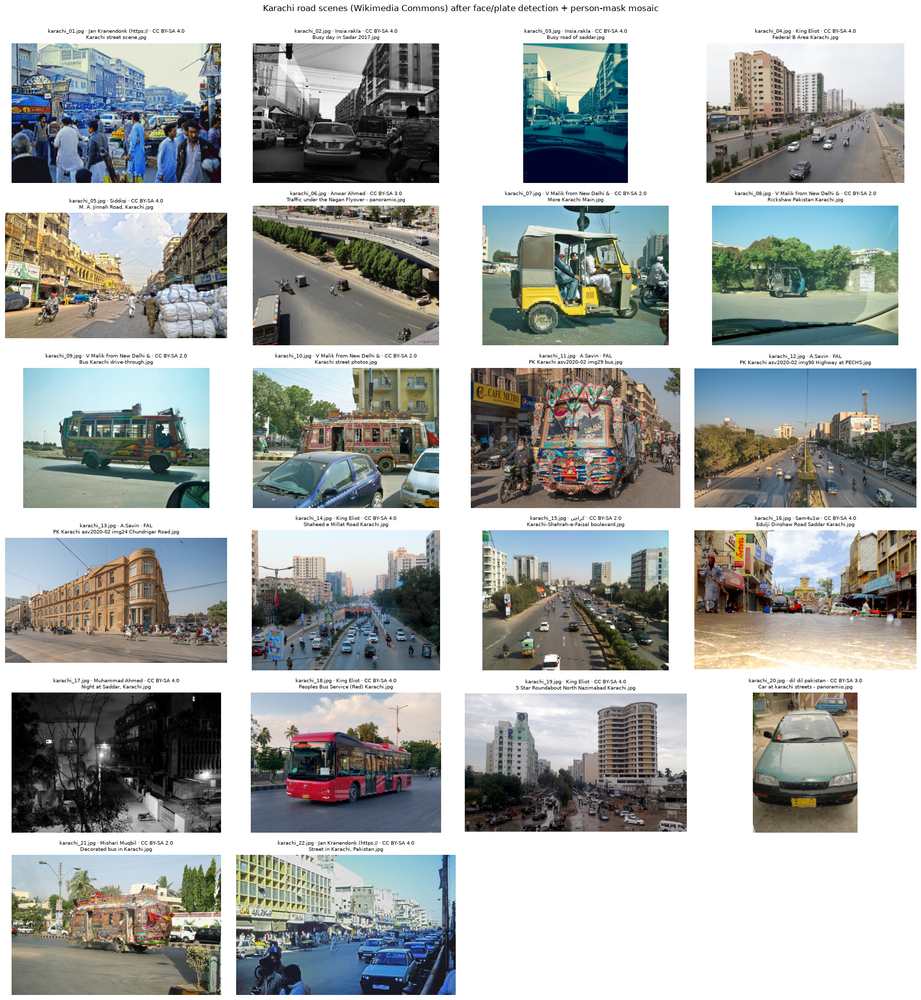

In [8]:
n = len(show); cols = 4; rows = math.ceil(n / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4.6 * cols, 3.3 * rows))
for ax, (_, r) in zip(axes.flat, manifest.iterrows()):
    ax.imshow(load_rgb(ANON_DIR / r.file)); ax.axis("off")
    ax.set_title(f"{r.file} · {str(r.author)[:24]} · {r.license}\n{str(r.commons_title)[5:60]}", fontsize=7)
for ax in axes.flat[n:]: ax.axis("off")
plt.suptitle("Karachi road scenes (Wikimedia Commons) after face/plate detection + person-mask mosaic", y=1.0); plt.tight_layout(); plt.savefig(OUT_DIR / "images_anonymised.jpg", dpi=80); plt.show()

### 7.2 SegFormer‑B2 semantic overlays and confidence maps

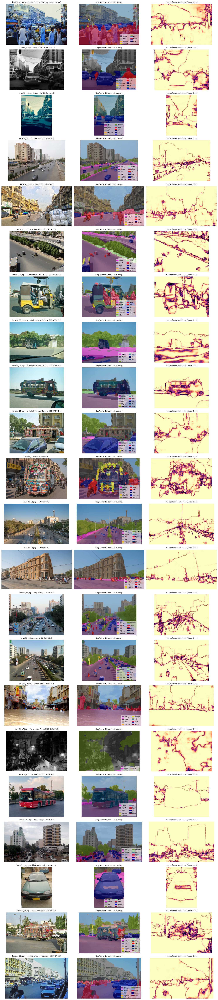

In [9]:
def legend_handles(labels_present):
    return [mpatches.Patch(color=PALETTE[i] / 255, label=NAMES[i]) for i in labels_present]

fig, axes = plt.subplots(len(show), 3, figsize=(15, 3.1 * len(show)))
for row, f in zip(axes, show):
    rgb = load_rgb(ANON_DIR / f); pred, conf = sem_results[f]["pred"], sem_results[f]["conf"]
    meta = manifest.set_index("file").loc[f]
    row[0].imshow(rgb); row[0].set_title(f"{f} — {str(meta.author)[:25]} ({meta.license})", fontsize=8)
    row[1].imshow(blend(rgb, pred)); row[1].set_title("SegFormer-B2 semantic overlay", fontsize=8)
    im = row[2].imshow(conf, cmap="magma", vmin=0.3, vmax=1); row[2].set_title(f"max-softmax confidence (mean {conf.mean():.2f})", fontsize=8)
    present = np.unique(pred); row[1].legend(handles=legend_handles(present), fontsize=5, loc="lower right", ncol=2, framealpha=.6)
    for a in row: a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "segformer_overlays.jpg", dpi=80); plt.show()

### 7.3 Mask2Former panoptic overlays (instances boxed and labelled)

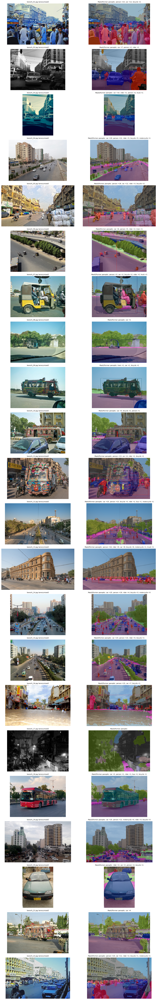

In [10]:
fig, axes = plt.subplots(len(show), 2, figsize=(13, 3.4 * len(show)))
for row, f in zip(axes, show):
    rgb2 = load_rgb(ANON_DIR / f); R = pan_results[f]
    things = [NAMES[s["label_id"]] for s in R["infos"] if NAMES[s["label_id"]] in THINGS]
    counts = pd.Series(things).value_counts().to_dict() if things else {}
    row[0].imshow(rgb2); row[0].set_title(f"{f} (anonymised)", fontsize=8)
    row[1].imshow(draw_instances(rgb2, R["seg"], R["infos"])); row[1].set_title("Mask2Former panoptic: " + ", ".join(f"{k} ×{v}" for k, v in counts.items())[:110], fontsize=8)
    for a in row: a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "mask2former_panoptic.jpg", dpi=80); plt.show()

## 8. Analysis
### 8.1 What is in a Karachi street? Pixel composition per image and overall

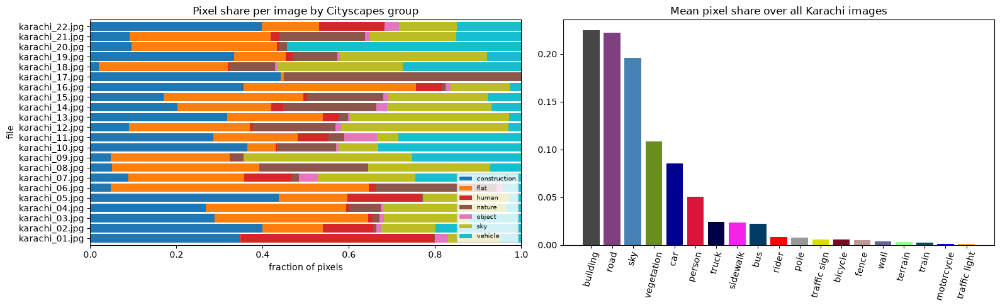

,building,road,sky,vegetation,car,person,truck,sidewalk,bus,rider,pole,traffic sign,bicycle,fence,wall,terrain,train,motorcycle,traffic light
mean pixel share,0.2246,0.2219,0.1958,0.1085,0.0851,0.0502,0.0239,0.0235,0.022,0.0085,0.0078,0.0059,0.0059,0.0051,0.0039,0.003,0.0025,0.0011,0.0008


In [11]:
rows = []
for f in show:
    pred, conf = sem_results[f]["pred"], sem_results[f]["conf"]
    share = np.bincount(pred.ravel(), minlength=19) / pred.size
    rec = dict(file=f, mean_conf=conf.mean(), low_conf_frac=(conf < 0.5).mean(), **{NAMES[i]: share[i] for i in range(19)})
    things = [NAMES[s["label_id"]] for s in pan_results[f]["infos"] if NAMES[s["label_id"]] in THINGS]
    vc = pd.Series(things).value_counts()
    rec.update({f"n_{t}": int(vc.get(t, 0)) for t in THINGS})
    rows.append(rec)
stats = pd.DataFrame(rows).set_index("file")
stats.to_csv(OUT_DIR / "per_image_stats.csv")

grp_share = stats[NAMES].T.groupby(lambda n: GROUP[n]).sum().T
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
grp_share.plot.barh(stacked=True, ax=ax[0], width=.85, colormap="tab10"); ax[0].set_title("Pixel share per image by Cityscapes group"); ax[0].set_xlabel("fraction of pixels"); ax[0].legend(fontsize=7, loc="lower right")
overall = stats[NAMES].mean().sort_values(ascending=False)
ax[1].bar(overall.index, overall.values, color=PALETTE[[NAMES.index(n) for n in overall.index]] / 255); ax[1].set_title("Mean pixel share over all Karachi images"); ax[1].tick_params(axis="x", rotation=75)
plt.tight_layout(); plt.savefig(OUT_DIR / "pixel_composition.png", dpi=120); plt.show()
overall.round(4).to_frame("mean pixel share").T

### 8.2 Traffic mix — what the panoptic model counted
Two Karachi‑specific indicators:
* **two‑wheeler ratio** = (motorcycle + bicycle predictions) / (cars + two‑wheelers) — high values mean mixed, motorbike‑heavy traffic. Bicycle predictions are included because, as the audit below shows, the slim 70 cc motorbikes that dominate Karachi traffic are frequently labelled *bicycle* by a Cityscapes model;
* **people on scene** = person + rider instances — pedestrians sharing the carriageway are common in Karachi and rare in Cityscapes.

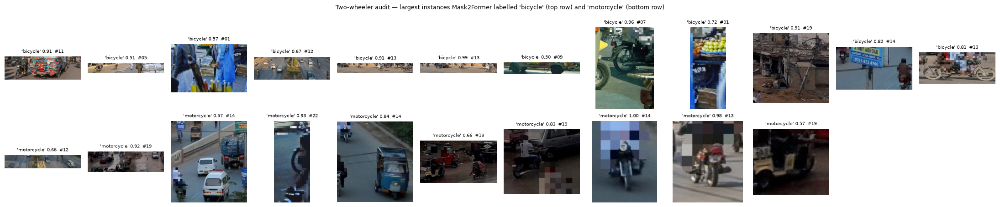

In [12]:
def instance_crops(cls_name, max_n=12, pad=12, min_px=400):
    crops = []
    for f in show:
        R = pan_results[f]; rgb = load_rgb(ANON_DIR / f)
        for s in R["infos"]:
            if NAMES[s["label_id"]] != cls_name: continue
            ys, xs = np.where(R["seg"] == s["id"])
            if len(ys) < min_px: continue
            y0, y1, x0, x1 = max(0, ys.min() - pad), ys.max() + pad, max(0, xs.min() - pad), xs.max() + pad
            crops.append((f, s["score"], rgb[y0:y1, x0:x1]))
    return sorted(crops, key=lambda c: -c[2].size)[:max_n]

fig, axes = plt.subplots(2, 12, figsize=(22, 4.6))
for r_, cls_name in enumerate(["bicycle", "motorcycle"]):
    cr = instance_crops(cls_name)
    for j in range(12):
        ax = axes[r_, j]; ax.axis("off")
        if j < len(cr): f, sc, im = cr[j]; ax.imshow(im); ax.set_title(f"'{cls_name}' {sc:.2f}  {f.replace('karachi_', '#').replace('.jpg', '')}", fontsize=7)
plt.suptitle("Two-wheeler audit — largest instances Mask2Former labelled 'bicycle' (top row) and 'motorcycle' (bottom row)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "two_wheeler_audit.jpg", dpi=90); plt.show()

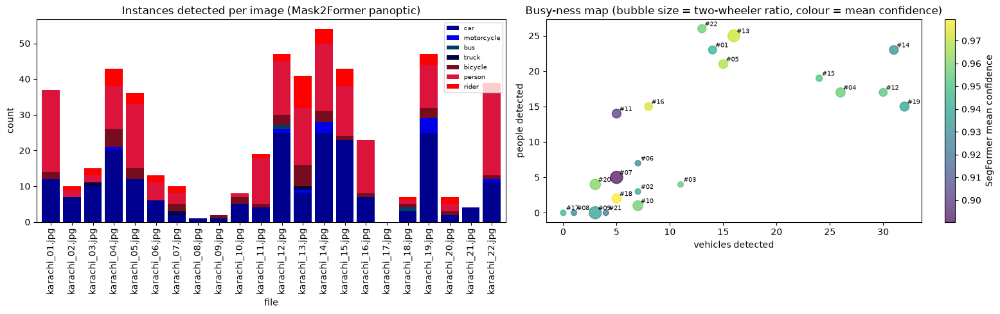

Totals over all images:
{'car': 213, 'motorcycle': 11, 'bus': 2, 'truck': 3, 'bicycle': 36, 'person': 197, 'rider': 44}
two-wheeler ratio (all images, motorcycle+bicycle): 0.18


,person,rider,car,truck,bus,train,motorcycle,bicycle,two_wheelers,two_wheeler_ratio,people,vehicles
file,,,,,,,,,,,,
karachi_01.jpg,23,0,12,0,0,0,0,2,2,0.14,23,14
karachi_02.jpg,2,1,7,0,0,0,0,0,0,0.00,3,7
karachi_03.jpg,2,2,10,1,0,0,0,0,0,0.00,4,11
karachi_04.jpg,12,5,20,0,0,0,1,5,6,0.23,17,26
karachi_05.jpg,18,3,12,0,0,0,0,3,3,0.20,21,15
karachi_06.jpg,5,2,6,0,0,1,0,0,0,0.00,7,7
karachi_07.jpg,3,2,2,1,0,0,0,2,2,0.50,5,5
karachi_08.jpg,0,0,1,0,0,0,0,0,0,0.00,0,1
karachi_09.jpg,0,0,1,0,0,1,0,1,1,0.50,0,3


In [13]:
cnt = stats[[f"n_{t}" for t in THINGS]].copy(); cnt.columns = THINGS
cnt["two_wheelers"] = cnt["motorcycle"] + cnt["bicycle"]
cnt["two_wheeler_ratio"] = cnt["two_wheelers"] / (cnt["car"] + cnt["two_wheelers"]).clip(lower=1)
cnt["people"] = cnt["person"] + cnt["rider"]
cnt["vehicles"] = cnt[["car", "truck", "bus", "train", "motorcycle", "bicycle"]].sum(1)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
cnt[["car", "motorcycle", "bus", "truck", "bicycle", "person", "rider"]].plot.bar(stacked=True, ax=ax[0], width=.85, color=[PALETTE[NAMES.index(c)] / 255 for c in ["car", "motorcycle", "bus", "truck", "bicycle", "person", "rider"]])
ax[0].set_title("Instances detected per image (Mask2Former panoptic)"); ax[0].set_ylabel("count"); ax[0].legend(fontsize=7)
ax[1].scatter(cnt["vehicles"], cnt["people"], s=40 + 300 * cnt["two_wheeler_ratio"], alpha=.7, c=stats["mean_conf"], cmap="viridis")
for f, r in cnt.iterrows(): ax[1].annotate(f.replace("karachi_", "#").replace(".jpg", ""), (r.vehicles, r.people), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("vehicles detected"); ax[1].set_ylabel("people detected"); ax[1].set_title("Busy-ness map (bubble size = two-wheeler ratio, colour = mean confidence)")
plt.colorbar(ax[1].collections[0], ax=ax[1], label="SegFormer mean confidence")
plt.tight_layout(); plt.savefig(OUT_DIR / "traffic_mix.png", dpi=120); plt.show()
print("Totals over all images:"); print(cnt[["car", "motorcycle", "bus", "truck", "bicycle", "person", "rider"]].sum().to_dict())
print(f"two-wheeler ratio (all images, motorcycle+bicycle): {cnt['two_wheelers'].sum() / max(1, cnt['car'].sum() + cnt['two_wheelers'].sum()):.2f}")
cnt.round(2)

### 8.3 Where does the Cityscapes → Karachi domain gap show up?
Low max‑softmax confidence is a well‑known proxy for distribution shift. We (i) measure the mean confidence
**per predicted class**, (ii) crop the lowest‑confidence regions to see *what* confuses the model, and
(iii) check how often the two independent models **disagree**.

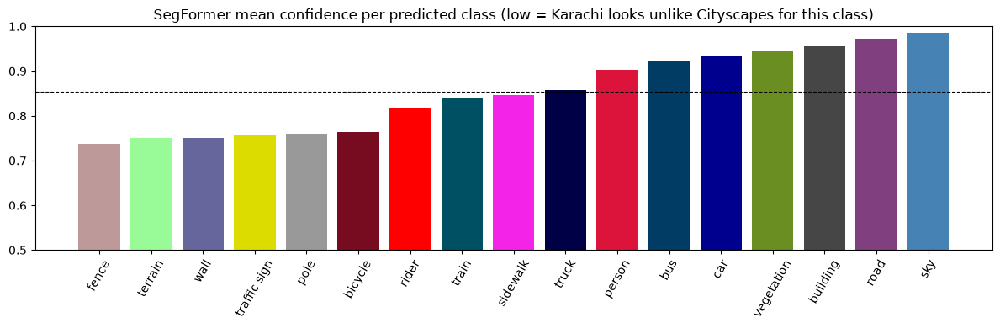

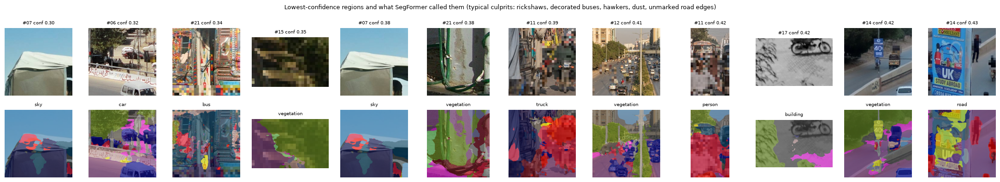

SegFormer vs Mask2Former pixel agreement: mean 0.830  (min 0.564 on karachi_16.jpg)
correlation(agreement, SegFormer confidence) = 0.54


file,karachi_01.jpg,karachi_02.jpg,karachi_03.jpg,karachi_04.jpg,karachi_05.jpg,karachi_06.jpg,karachi_07.jpg,karachi_08.jpg,karachi_09.jpg,karachi_10.jpg,...,karachi_13.jpg,karachi_14.jpg,karachi_15.jpg,karachi_16.jpg,karachi_17.jpg,karachi_18.jpg,karachi_19.jpg,karachi_20.jpg,karachi_21.jpg,karachi_22.jpg
pixel_agreement,0.862,0.874,0.915,0.925,0.855,0.809,0.69,0.664,0.777,0.925,...,0.967,0.860,0.909,0.564,0.842,0.956,0.857,0.855,0.773,0.863
unlabelled_by_m2f,0.034,0.024,0.000,0.001,0.002,0.020,0.00,0.005,0.001,0.003,...,0.001,0.001,0.002,0.000,0.000,0.000,0.001,0.006,0.001,0.003
mean_conf,0.944,0.941,0.956,0.956,0.968,0.927,0.89,0.927,0.938,0.958,...,0.972,0.931,0.951,0.974,0.947,0.979,0.939,0.960,0.921,0.957


In [14]:
per_class_conf, per_class_pix = np.zeros(19), np.zeros(19)
for f in show:
    pred, conf = sem_results[f]["pred"], sem_results[f]["conf"]
    for c in range(19):
        m = pred == c; per_class_conf[c] += conf[m].sum(); per_class_pix[c] += m.sum()
cc = pd.DataFrame(dict(cls=NAMES, mean_conf=per_class_conf / np.maximum(per_class_pix, 1), pixel_share=per_class_pix / per_class_pix.sum()))
cc = cc[cc.pixel_share > 0.001].sort_values("mean_conf")
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(cc.cls, cc.mean_conf, color=PALETTE[[NAMES.index(n) for n in cc.cls]] / 255); ax.axhline(cc.mean_conf.mean(), ls="--", c="k", lw=.8)
ax.set_ylim(0.5, 1); ax.set_title("SegFormer mean confidence per predicted class (low = Karachi looks unlike Cityscapes for this class)"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(OUT_DIR / "confidence_per_class.png", dpi=120); plt.show()

# (ii) crops around the least-confident regions
crops = []
for f in show:
    conf = sem_results[f]["conf"]; small = cv2.resize(conf, (conf.shape[1] // 32, conf.shape[0] // 32), interpolation=cv2.INTER_AREA)
    yy, xx = np.unravel_index(np.argsort(small.ravel())[:2], small.shape)
    for y, x in zip(yy, xx):
        crops.append((f, float(small[y, x]), slice(max(0, y * 32 - 96), y * 32 + 128), slice(max(0, x * 32 - 96), x * 32 + 128)))
crops = sorted(crops, key=lambda c: c[1])[:12]
fig, axes = plt.subplots(2, 12, figsize=(22, 4))
for j, (f, cval, sy, sx) in enumerate(crops):
    rgb = load_rgb(ANON_DIR / f); pred = sem_results[f]["pred"]
    axes[0, j].imshow(rgb[sy, sx]); axes[0, j].set_title(f"{f.replace('karachi_', '#').replace('.jpg', '')} conf {cval:.2f}", fontsize=7)
    axes[1, j].imshow(blend(rgb[sy, sx], pred[sy, sx], .6)); axes[1, j].set_title(NAMES[np.bincount(pred[sy, sx].ravel(), minlength=19).argmax()], fontsize=7)
    for a in axes[:, j]: a.axis("off")
plt.suptitle("Lowest-confidence regions and what SegFormer called them (typical culprits: rickshaws, decorated buses, hawkers, dust, unmarked road edges)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "low_confidence_crops.jpg", dpi=90); plt.show()

# (iii) model agreement
agree = []
for f in show:
    a, b = sem_results[f]["pred"], pan_results[f]["sem"]; valid = b != 255
    agree.append(dict(file=f, pixel_agreement=(a[valid] == b[valid]).mean(), unlabelled_by_m2f=(~valid).mean(), mean_conf=sem_results[f]["conf"].mean()))
agree = pd.DataFrame(agree).set_index("file"); agree.to_csv(OUT_DIR / "model_agreement.csv")
print(f"SegFormer vs Mask2Former pixel agreement: mean {agree.pixel_agreement.mean():.3f}  (min {agree.pixel_agreement.min():.3f} on {agree.pixel_agreement.idxmin()})")
print(f"correlation(agreement, SegFormer confidence) = {agree.pixel_agreement.corr(agree.mean_conf):.2f}")
agree.round(3).T

### 8.4 Confusion between the two models (which Cityscapes classes get swapped on Karachi roads?)

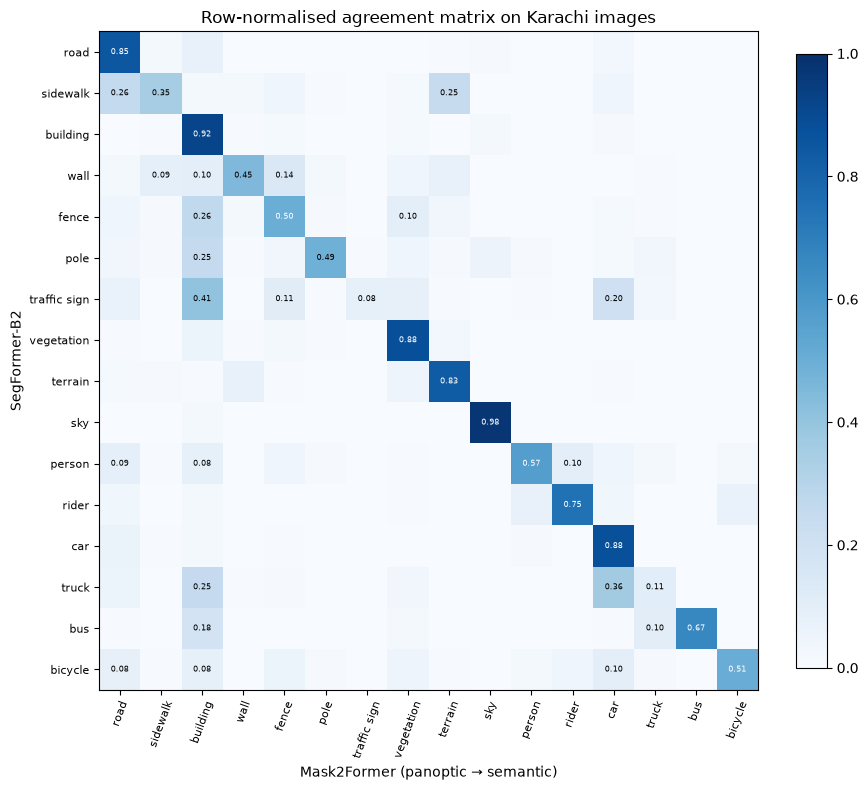

Systematic disagreements (>10% of a class):
  SegFormer 'traffic sign'  ->  Mask2Former 'building'  (41%)
  SegFormer 'truck'  ->  Mask2Former 'car'  (36%)
  SegFormer 'fence'  ->  Mask2Former 'building'  (26%)
  SegFormer 'sidewalk'  ->  Mask2Former 'road'  (26%)
  SegFormer 'pole'  ->  Mask2Former 'building'  (25%)
  SegFormer 'truck'  ->  Mask2Former 'building'  (25%)
  SegFormer 'sidewalk'  ->  Mask2Former 'terrain'  (25%)
  SegFormer 'traffic sign'  ->  Mask2Former 'car'  (20%)
  SegFormer 'bus'  ->  Mask2Former 'building'  (18%)
  SegFormer 'wall'  ->  Mask2Former 'fence'  (14%)
  SegFormer 'traffic sign'  ->  Mask2Former 'fence'  (11%)
  SegFormer 'bus'  ->  Mask2Former 'truck'  (10%)


[None, None, None, None, None, None, None, None, None, None, None, None]

In [15]:
cm = np.zeros((19, 19), np.int64)
for f in show:
    a, b = sem_results[f]["pred"].ravel(), pan_results[f]["sem"].ravel(); v = b != 255
    np.add.at(cm, (a[v], b[v]), 1)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
keep = [i for i in range(19) if cm[i].sum() > 0.002 * cm.sum()]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn[np.ix_(keep, keep)], cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(keep))); ax.set_xticklabels([NAMES[i] for i in keep], rotation=70, fontsize=8); ax.set_yticks(range(len(keep))); ax.set_yticklabels([NAMES[i] for i in keep], fontsize=8)
ax.set_xlabel("Mask2Former (panoptic → semantic)"); ax.set_ylabel("SegFormer-B2"); ax.set_title("Row-normalised agreement matrix on Karachi images")
for i in range(len(keep)):
    for j in range(len(keep)):
        if cmn[keep[i], keep[j]] > 0.08: ax.text(j, i, f"{cmn[keep[i], keep[j]]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[keep[i], keep[j]] > .5 else "black")
plt.colorbar(im, fraction=.04); plt.tight_layout(); plt.savefig(OUT_DIR / "model_confusion.png", dpi=120); plt.show()
off = [(NAMES[i], NAMES[j], cmn[i, j]) for i in keep for j in keep if i != j and cmn[i, j] > 0.1]
print("Systematic disagreements (>10% of a class):"); [print(f"  SegFormer '{a}'  ->  Mask2Former '{b}'  ({v:.0%})") for a, b, v in sorted(off, key=lambda t: -t[2])]

### 8.5 Export pseudo‑labels for fine‑tuning (bridge to notebook 01)
The Cityscapes models give usable but imperfect labels on Karachi. A standard remedy is **self‑training**: keep
only confident pixels as pseudo‑labels (`255` = ignore) and fine‑tune a lighter network (e.g. the UNet++ from
`01_unet_unetpp_framework.ipynb` with `num_classes=19`) on them, ideally together with a few hand‑corrected masks.

In [16]:
PSEUDO = Path("../data/karachi_pseudo"); (PSEUDO / "images").mkdir(parents=True, exist_ok=True); (PSEUDO / "masks").mkdir(exist_ok=True)
kept = []
for f in show:
    pred, conf = sem_results[f]["pred"], sem_results[f]["conf"]; m2f = pan_results[f]["sem"]
    lab = pred.copy(); lab[(conf < 0.7) | ((m2f != 255) & (m2f != pred))] = 255     # keep pixels that are confident AND agreed by both models
    Image.open(ANON_DIR / f).save(PSEUDO / "images" / f); Image.fromarray(lab).save(PSEUDO / "masks" / f.replace(".jpg", ".png"))
    kept.append((lab != 255).mean())
print(f"pseudo-labels written to {PSEUDO}  | labelled pixel fraction: mean {np.mean(kept):.2f}, min {np.min(kept):.2f}")
print("To fine-tune: Config(images_dir='../data/karachi_pseudo/images', masks_dir='../data/karachi_pseudo/masks', num_classes=19) in notebook 01 (add ignore_index=255 to the CE loss).")

pseudo-labels written to ..\data\karachi_pseudo  | labelled pixel fraction: mean 0.80, min 0.55
To fine-tune: Config(images_dir='../data/karachi_pseudo/images', masks_dir='../data/karachi_pseudo/masks', num_classes=19) in notebook 01 (add ignore_index=255 to the CE loss).


## 9. Findings & discussion

Fill in after running — the cell below prints the numbers the discussion refers to.

In [17]:
summary = dict(
    n_images=len(show),
    mean_segformer_confidence=round(float(stats.mean_conf.mean()), 3),
    low_confidence_pixel_fraction=round(float(stats.low_conf_frac.mean()), 3),
    model_pixel_agreement=round(float(agree.pixel_agreement.mean()), 3),
    top5_pixel_share={k: round(float(v), 3) for k, v in overall.head(5).items()},
    instances_total=cnt[["car", "motorcycle", "bus", "truck", "bicycle", "person", "rider"]].sum().astype(int).to_dict(),
    two_wheeler_ratio_motorcycle_plus_bicycle=round(float(cnt["two_wheelers"].sum() / max(1, cnt["car"].sum() + cnt["two_wheelers"].sum())), 2),
    least_confident_classes=cc.head(4).cls.tolist(),
    most_confident_classes=cc.tail(3).cls.tolist()[::-1],
    busiest_image_by_instances=str(cnt["vehicles"].add(cnt["people"]).idxmax()),
    anonymisation=anon_log.sum(numeric_only=True).astype(int).to_dict(),
)
json.dump(summary, open(OUT_DIR / "summary.json", "w"), indent=1)
print(json.dumps(summary, indent=1))

{
 "n_images": 22,
 "mean_segformer_confidence": 0.945,
 "low_confidence_pixel_fraction": 0.02,
 "model_pixel_agreement": 0.83,
 "top5_pixel_share": {
  "building": 0.225,
  "road": 0.222,
  "sky": 0.196,
  "vegetation": 0.109,
  "car": 0.085
 },
 "instances_total": {
  "car": 213,
  "motorcycle": 11,
  "bus": 2,
  "truck": 3,
  "bicycle": 36,
  "person": 197,
  "rider": 44
 },
 "two_wheeler_ratio_motorcycle_plus_bicycle": 0.18,
 "least_confident_classes": [
  "fence",
  "terrain",
  "wall",
  "traffic sign"
 ],
 "most_confident_classes": [
  "sky",
  "road",
  "building"
 ],
 "busiest_image_by_instances": "karachi_14.jpg",
 "anonymisation": {
  "faces_blurred": 50,
  "plates_blurred": 5,
  "people_mosaiced": 241,
  "vehicle_plate_zones": 75
 }
}


**What the two Cityscapes‑trained models get right on Karachi roads**
* *Stuff* classes transfer well. Building (≈22 % of pixels), road (≈22 %), sky (≈20 %) and vegetation (≈11 %) are segmented cleanly; they are also the classes with the highest confidence (sky ≈ 0.99, road ≈ 0.97, building ≈ 0.95), and only ≈ 2 % of all pixels fall below 0.5 confidence.
* Cars and people are found reliably even in dense scenes (≈ 210 cars and ≈ 240 persons + riders across 22 photos); the two independent models agree on ≈ 83 % of pixels, and agreement tracks SegFormer's confidence (ρ ≈ 0.5), so confidence is a usable quality signal without any Karachi labels.

**Where the 50‑European‑city prior breaks**
* **Two‑ and three‑wheelers are mislabelled.** The panoptic model returned ≈ 3× more *bicycle* than *motorcycle* instances although Karachi has very few bicycles. The audit crops labelled *bicycle* are motorbikes with riders, rows of parked motorbikes merged into one segment, a hand‑cart and even a rickshaw; a third of the *motorcycle* crops are auto‑rickshaws/qingqis. Counting by raw class name therefore under‑counts Karachi's dominant vehicle types (two‑wheelers come out at only 18 % of car + two‑wheeler instances).
* **Classes that do not exist in Cityscapes** — auto‑rickshaws, qingqis, hand‑carts, hawkers' stalls, roadside goods — are forced into *motorcycle / bicycle / car / truck / building / sky* and are exactly where the lowest‑confidence crops come from (a rickshaw canopy called *sky* at 0.30 confidence; a decorated bus body called *bus*/*truck* at 0.35).
* **Appearance shift** — decorated buses are split between *bus*, *truck*, *train* and *building* (only 2 *bus* instances for ≥ 5 visible buses); Urdu signboards on façades make *traffic sign* vs *building* the largest inter‑model disagreement (≈ 40 %); fence, terrain, wall, traffic sign and pole are the least confident classes. The one night image returned no instances at all — Cityscapes has no night data.
* **Scene layout** — no kerbed sidewalks or cycle lanes: SegFormer's *sidewalk* is re‑labelled *road* or *terrain* by Mask2Former a quarter of the time (dusty shoulders), and *truck* ↔ *car* confusion (≈ 36 %) reflects Suzuki pick‑ups and vans that sit between the two Cityscapes classes.

**Why it matters / what to do next**
1. Collect a small, consented Karachi dataset (anonymised as above) and label at least the missing classes; the *India Driving Dataset* (IDD) shows the template — it adds *autorickshaw*, *animal*, *drivable fallback* etc.
2. Self‑train or fine‑tune (see §8.5) — UNet++/SegFormer fine‑tuning on a few hundred local images typically recovers most of the gap.
3. Report performance *per city/region*; a model validated only on Cityscapes should not be deployed for safety‑critical use in South Asia.